# 2J — Directional transporter control vs metabolite value

**Motivation.** The number of affected strains and the *mean |effect|* per metabolite show no
relationship with metabolite value (Fig. 5 / notebook 2G). Both metrics discard the *sign* of
the effect, yet the paper's mechanism is directional:

- **Positive effect** (KO increases release) → the transporter normally *counteracts* release
  (re-uptake / salvage).
- **Negative effect** (KO decreases release) → the transporter normally *causes* release
  (export / leak).

Here we test whether metabolite value relates to the **direction** of transporter control,
with guardrails for the detection-breadth confound and metabolite-class structure.

In [1]:
import pandas as pd, numpy as np, scipy.stats as st
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from scipy.stats import rankdata
import statsmodels.formula.api as smf

repo_folder = Path('../../..')
data_folder = repo_folder/'data'/'this_project'/'6_transporterKO'
mfolder = data_folder/'D_big_screen'
figure_folder = repo_folder/'figures'/'3_big_screen'
norm='TIC'; lam=10; xval='AUC OD'; max_pval=0.005; min_effect=3

## Load effects, annotation, value and transporter direction

In [2]:
df_ionMz = pd.read_csv(mfolder/'H_ionMz_annotation.csv').drop_duplicates(subset=['ionMz'])
dis_df = pd.read_csv(mfolder/f'K_timecurve_comparison_{norm}_norm_lam_{lam}_{xval}.csv', index_col=0)
dis_mz = dis_df.merge(df_ionMz, on='ionMz', how='left')
dis_mz = dis_mz[~dis_mz.Strain.isin(['dppB','tolC','ptsG'])]          # drop slow strains
sel_df = dis_mz[(dis_mz['Rel. distance'].abs()>min_effect) &
                (dis_mz['p-value rel']<max_pval)].copy()               # significant effects
print('all pairs:', len(dis_mz), '| significant:', len(sel_df))

all pairs: 15848 | significant: 722


In [3]:
# metabolite value (mean over KEGG ids), transporter expected direction
dfv = pd.read_csv(data_folder/'Z_div/I_metabolite_values_big_screen.csv')
dfv['logv'] = np.log10(dfv['Metabolite value'])
k2lv = dfv.set_index('kegg_id')['logv'].to_dict()
def met_lv(k):
    if pd.isna(k): return np.nan
    vals=[k2lv.get(x,np.nan) for x in k.split(';')]
    return np.nan if all(pd.isna(vals)) else np.nanmean(vals)

ann = df_ionMz.drop_duplicates('Metabolite')[['Metabolite','KEGG','Classification']].copy()
ann['logv'] = ann['KEGG'].apply(met_lv)
met2lv  = ann.set_index('Metabolite')['logv'].to_dict()
met2cls = ann.set_index('Metabolite')['Classification'].to_dict()

tm = pd.read_csv(data_folder/'B_selected_transporters_with_expression_levels.csv')
s2dir = tm.set_index('Gene Name')['Expected direction'].to_dict()

for d in (dis_mz, sel_df):
    d['logv'] = d['Metabolite'].map(met2lv)
    d['dir']  = d['Strain'].map(s2dir)
    d['Classification'] = d['Metabolite'].map(met2cls)

## Per-metabolite directional scores

- **frac_pos** = N_pos / (N_pos + N_neg) over *significant* effects (salvage-dominated ⇒ high).
- **net**      = N_pos − N_neg.
- **mean_signed_all** = mean signed effect over *all* strains (no significance threshold).
- **N_total**  = number of strains the metabolite was tested in (detection breadth = confound).

In [4]:
pos = sel_df[sel_df['Rel. distance']>0].groupby('Metabolite').size().rename('N_pos')
neg = sel_df[sel_df['Rel. distance']<0].groupby('Metabolite').size().rename('N_neg')
sig = pd.concat([pos,neg],axis=1).fillna(0)
sig['N_sig']   = sig.N_pos + sig.N_neg
sig['frac_pos']= sig.N_pos / sig.N_sig
sig['net']     = sig.N_pos - sig.N_neg

mean_signed = dis_mz.groupby('Metabolite')['Rel. distance'].mean().rename('mean_signed_all')
n_total     = dis_mz.groupby('Metabolite')['Strain'].count().rename('N_total')

m = (ann.merge(sig, on='Metabolite', how='left')
        .merge(mean_signed, on='Metabolite', how='left')
        .merge(n_total, on='Metabolite', how='left')
        .dropna(subset=['logv']))
m.head()

,Metabolite,KEGG,Classification,logv,N_pos,N_neg,N_sig,frac_pos,net,mean_signed_all,N_total
1,Acetatic acid,C00033;C00266,Mixed,-2.005533,1.0,0.0,1.0,1.0,1.0,0.193407,63
2,Pyruvaldehyde,C00546,Organic oxygen compounds,-1.542093,NaN,NaN,NaN,NaN,NaN,-0.202410,63
3,Iminoacetate,C15809,Unknown,-0.724887,NaN,NaN,NaN,NaN,NaN,-0.124199,53
4,Glyoxylic acid,C00048,Carboxylic acids,-1.902960,NaN,NaN,NaN,NaN,NaN,-0.121826,53
5,C3:0 (Propionic acid),C00163;C00424;C00937;C05999,Mixed,-1.479430,1.0,1.0,2.0,0.5,0.0,-0.102820,63


In [5]:
def sp(x,y):
    s=pd.DataFrame({'x':x,'y':y}).dropna()
    if len(s)<5: return dict(r=np.nan,p=np.nan,n=len(s))
    r,p=st.spearmanr(s.x,s.y); return dict(r=r,p=p,n=len(s))

def perm_p(x,y,n=5000,seed=0):
    s=pd.DataFrame({'x':x,'y':y}).dropna(); rng=np.random.default_rng(seed)
    obs=st.spearmanr(s.x,s.y)[0]; xv=s.x.values.copy(); yv=s.y.values
    d=[st.spearmanr(np.random.default_rng(i).permutation(xv),yv)[0] for i in range(n)]
    return obs, np.mean(np.abs(d)>=abs(obs))

print('frac_pos vs value (N_sig>=3):', sp(m[m.N_sig>=3].logv, m[m.N_sig>=3].frac_pos))
print('net vs value      (N_sig>=3):', sp(m[m.N_sig>=3].logv, m[m.N_sig>=3].net))
print('mean_signed_all vs value    :', sp(m.logv, m.mean_signed_all))
print('CONFOUND value vs N_total   :', sp(m.logv, m.N_total))

# partial Spearman: value vs mean_signed controlling detection breadth
def partial_sp(a,b,ctrl):
    s=pd.DataFrame({'a':a,'b':b,'c':ctrl}).dropna()
    ra,rb,rc=rankdata(s.a),rankdata(s.b),rankdata(s.c)
    resid=lambda y,x:(y-np.c_[np.ones_like(x),x]@np.linalg.lstsq(np.c_[np.ones_like(x),x],y,rcond=None)[0])
    r,p=st.pearsonr(resid(ra,rc),resid(rb,rc)); return dict(r=r,p=p,n=len(s))
print('partial(value, mean_signed | N_total):', partial_sp(m.logv,m.mean_signed_all,m.N_total))
obs,pp=perm_p(m.logv,m.mean_signed_all); print(f'permutation P(mean_signed): obs r={obs:.3f} P={pp:.4f}')

frac_pos vs value (N_sig>=3): {'r': np.float64(-0.26949344915863815), 'p': np.float64(0.03570274753016624), 'n': 61}
net vs value      (N_sig>=3): {'r': np.float64(-0.2608588587255902), 'p': np.float64(0.042302912127533523), 'n': 61}
mean_signed_all vs value    : {'r': np.float64(-0.12371061216159744), 'p': np.float64(0.07362854351460238), 'n': 210}
CONFOUND value vs N_total   : {'r': np.float64(-0.35816382178284917), 'p': np.float64(9.426948636245789e-08), 'n': 210}
partial(value, mean_signed | N_total): {'r': np.float64(-0.18070583897791048), 'p': np.float64(0.0086727993311707), 'n': 210}


permutation P(mean_signed): obs r=-0.124 P=0.0728


## Pair-level signed effect vs value, split by transporter direction

Caveat: strain–metabolite pairs are **not independent** (value is a per-metabolite property, so
each metabolite contributes many pairs). Pair-level P-values are anticonservative — read them as
descriptive, and rely on the per-metabolite and class-controlled tests below for inference.

In [6]:
print('--- significant pairs (sel_df) ---')
for dn,g in sel_df.groupby('dir'): print(f'{dn:7s}', sp(g.logv, g['Rel. distance']))
print('ALL   ', sp(sel_df.logv, sel_df['Rel. distance']))

# class-controlled OLS on significant pairs
d = sel_df.dropna(subset=['logv','dir']).rename(columns={'Rel. distance':'eff'})
mod = smf.ols('eff ~ logv * C(dir) + C(Classification)', data=d).fit()
print(f'\nOLS eff ~ logv*dir + class : P(logv)={mod.pvalues["logv"]:.3g}  R2={mod.rsquared:.3f}  n={int(mod.nobs)}')

--- significant pairs (sel_df) ---
Both    {'r': np.float64(-0.3019693022832332), 'p': np.float64(0.001744211549670221), 'n': 105}
Export  {'r': np.float64(-0.24561950550653486), 'p': np.float64(0.0014732003865504976), 'n': 165}
Import  {'r': np.float64(-0.17010165872981867), 'p': np.float64(0.002375337805223864), 'n': 317}
ALL    {'r': np.float64(-0.20162206640850308), 'p': np.float64(8.428641989655124e-07), 'n': 587}

OLS eff ~ logv*dir + class : P(logv)=0.209  R2=0.133  n=587


## Figure

saved ../../../figures/3_big_screen/figure_5_directional_control_vs_value_TIC_norm_lam_10


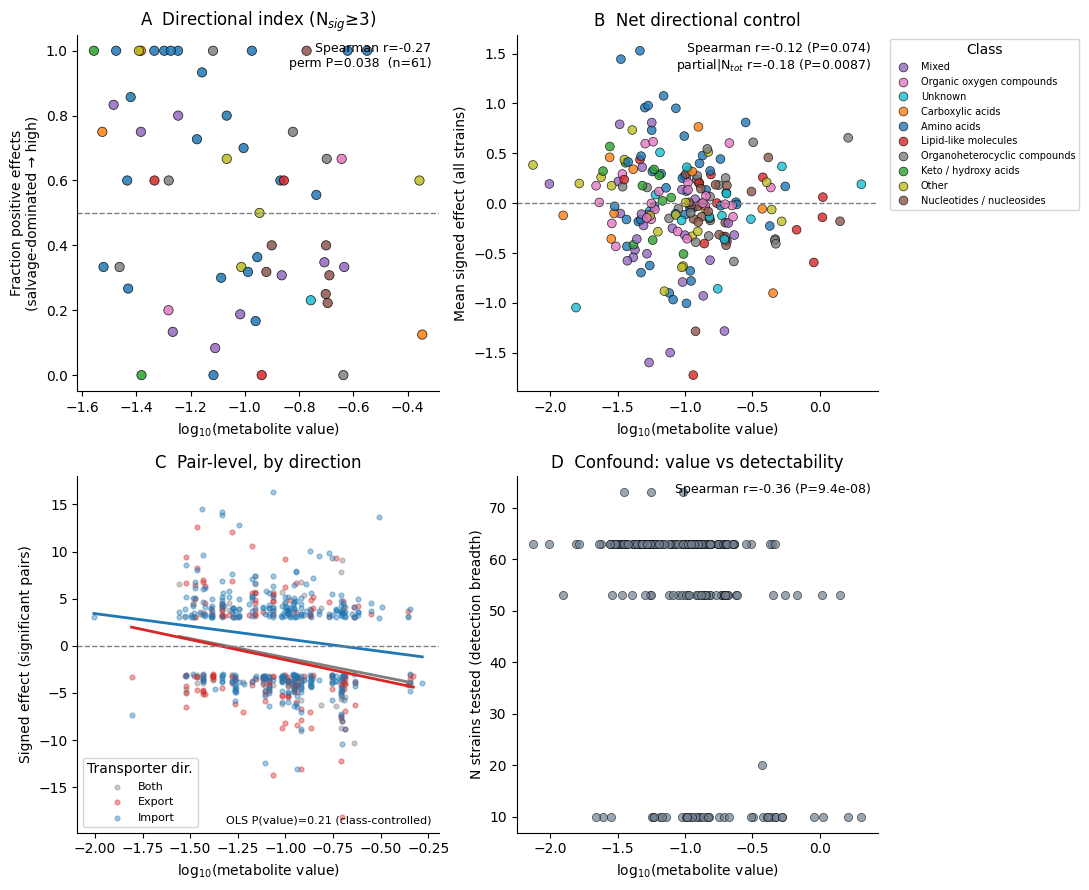

In [7]:
try: from matplotlib import cm; class_to_color={cls:cm.tab10(i%10) for i,cls in enumerate(sorted(m.Classification.dropna().unique()))}
except Exception: class_to_color=None

fig, axes = plt.subplots(2,2, figsize=(11,9)); axes=axes.ravel()

# A frac_pos vs value
ax=axes[0]; s=m[m.N_sig>=3]
sns.scatterplot(data=s,x='logv',y='frac_pos',hue='Classification',palette=class_to_color,
                edgecolor='k',s=45,alpha=.85,ax=ax,legend=False)
ax.axhline(.5,ls='--',c='grey',lw=1)
st1=sp(s.logv,s.frac_pos); o,pp=perm_p(s.logv,s.frac_pos)
ax.text(.98,.98,f"Spearman r={st1['r']:.2f}\nperm P={pp:.3f}  (n={st1['n']})",transform=ax.transAxes,va='top',ha='right',fontsize=9)
ax.set(xlabel='log$_{10}$(metabolite value)',ylabel='Fraction positive effects\n(salvage-dominated → high)',title='A  Directional index (N$_{sig}$≥3)')

# B mean signed vs value
ax=axes[1]
sns.scatterplot(data=m,x='logv',y='mean_signed_all',hue='Classification',palette=class_to_color,
                edgecolor='k',s=40,alpha=.8,ax=ax)
ax.axhline(0,ls='--',c='grey',lw=1)
ps=partial_sp(m.logv,m.mean_signed_all,m.N_total); st2=sp(m.logv,m.mean_signed_all)
ax.text(.98,.98,f"Spearman r={st2['r']:.2f} (P={st2['p']:.2g})\npartial|N$_{{tot}}$ r={ps['r']:.2f} (P={ps['p']:.2g})",
        transform=ax.transAxes,va='top',ha='right',fontsize=9)
ax.set(xlabel='log$_{10}$(metabolite value)',ylabel='Mean signed effect (all strains)',title='B  Net directional control')
sns.move_legend(ax,'upper left',bbox_to_anchor=(1.02,1),frameon=True,title='Class',fontsize=7)

# C pair-level split by direction
ax=axes[2]
pal={'Import':'#1f77b4','Export':'#d62728','Both':'#7f7f7f'}
for dn,g in sel_df.groupby('dir'):
    ax.scatter(g.logv,g['Rel. distance'],s=12,alpha=.4,color=pal.get(dn,'k'),label=dn)
    gg=g[['logv','Rel. distance']].dropna()
    if len(gg)>10:
        b=np.polyfit(gg.logv,gg['Rel. distance'],1); xs=np.linspace(gg.logv.min(),gg.logv.max(),50)
        ax.plot(xs,np.polyval(b,xs),color=pal.get(dn,'k'),lw=2)
ax.axhline(0,ls='--',c='grey',lw=1); ax.legend(title='Transporter dir.',fontsize=8)
ax.text(.98,.02,f"OLS P(value)={mod.pvalues['logv']:.2g} (class-controlled)",transform=ax.transAxes,va='bottom',ha='right',fontsize=8)
ax.set(xlabel='log$_{10}$(metabolite value)',ylabel='Signed effect (significant pairs)',title='C  Pair-level, by direction')

# D confound
ax=axes[3]
sns.scatterplot(data=m,x='logv',y='N_total',ax=ax,color='slategray',edgecolor='k',s=35,alpha=.7)
stc=sp(m.logv,m.N_total)
ax.text(.98,.98,f"Spearman r={stc['r']:.2f} (P={stc['p']:.2g})",transform=ax.transAxes,va='top',ha='right',fontsize=9)
ax.set(xlabel='log$_{10}$(metabolite value)',ylabel='N strains tested (detection breadth)',title='D  Confound: value vs detectability')

sns.despine(); plt.tight_layout()
figure_folder.mkdir(parents=True,exist_ok=True)
out=figure_folder/f'figure_5_directional_control_vs_value_{norm}_norm_lam_{lam}'
plt.savefig(f'{out}.pdf',dpi=300,bbox_inches='tight'); plt.savefig(f'{out}.png',dpi=150,bbox_inches='tight')
print('saved', out)

## Summary

Unlike the sign-agnostic metrics, the **directional** analysis reveals a *consistent but weak
negative* trend: higher-value metabolites lean toward **transporter-caused release** (net-negative
control / lower fraction of salvage effects) — the opposite of a naive "salvage the expensive
stuff" hypothesis.

The trend is directionally consistent across every cut and survives the detection-breadth
confound (partial correlation), **but it does not survive class-controlled, per-metabolite
testing** (OLS P≈0.2). The apparent pair-level significance is inflated by pseudoreplication.
Bottom line: the directional axis is more informative than magnitude/count, but the value↔effect
link remains weak — consistent with, and sharpening, the manuscript's stated null.